<a href="https://colab.research.google.com/github/jeevaprakash-S/24ADI006_24BAD048/blob/main/24BAD048_JEEVAPRAKASH_EXPERIMENT_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q datasets tensorflow matplotlib numpy


## PART A: DATASET PREPARATION

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("24BAD048-Jeevaprakash S")

TensorFlow version: 2.20.0
24BAD048-Jeevaprakash S


In [3]:

from datasets import load_dataset, Dataset

try:
    raw_datasets = load_dataset("tiny_shakespeare")
    text_data = raw_datasets["train"]["text"][0]
    print("Loaded via datasets.load_dataset('tiny_shakespeare')")
except Exception as e:
    print("Falling back to direct download because:", e)
    import urllib.request
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    text_data = urllib.request.urlopen(url).read().decode("utf-8")
    raw_datasets = {"train": Dataset.from_dict({"text": [text_data]})}
    print("Loaded via direct download and wrapped as a HF Dataset")

print("Total characters in corpus:", len(text_data))


README.md:   0%|          | 0.00/6.10k [00:00<?, ?B/s]

tiny_shakespeare.py:   0%|          | 0.00/3.73k [00:00<?, ?B/s]

Falling back to direct download because: Dataset scripts are no longer supported, but found tiny_shakespeare.py
Loaded via direct download and wrapped as a HF Dataset
Total characters in corpus: 1115394


In [4]:
# ---- A.2 Explore the dataset ----
print("First 500 characters of the corpus:\n")
print(text_data[:500])
print("\n---\n")
print("Number of lines:", len(text_data.splitlines()))


First 500 characters of the corpus:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor

---

Number of lines: 40000


In [5]:
# ---- A.3 Convert text to lowercase ----
text_data_lower = text_data.lower()
print(text_data_lower[:300])


first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us


In [6]:
# ---- A.4 & A.5 Tokenize into words and build vocabulary ----
# To keep training tractable, use a manageable subset of the corpus (first N characters).
# Increase SUBSET_CHARS for a fuller (but slower) training run.
SUBSET_CHARS = 100000
corpus_text = text_data_lower[:SUBSET_CHARS]

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts([corpus_text])

vocab_size = len(tokenizer.word_index) + 1   # +1 for the padding index (0)
print("Vocabulary size (incl. OOV & padding index 0):", vocab_size)
print("Sample of word -> index mapping:")
for word, idx in list(tokenizer.word_index.items())[:15]:
    print(f"  {word!r:>15} -> {idx}")


Vocabulary size (incl. OOV & padding index 0): 3106
Sample of word -> index mapping:
          '<OOV>' -> 1
            'the' -> 2
             'to' -> 3
            'you' -> 4
            'and' -> 5
              'i' -> 6
             'of' -> 7
              'a' -> 8
           'that' -> 9
             'he' -> 10
             'in' -> 11
           'your' -> 12
            'not' -> 13
           'have' -> 14
             'it' -> 15


In [7]:
# ---- A.6 Generate input sequences for next-word prediction ----
# Build n-gram sequences line by line: for each line, every prefix of length >=2
# becomes a training example, where the last word is the label (next-word target).
lines = [l for l in corpus_text.split("\n") if l.strip() != ""]

input_sequences = []
for line in lines:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[: i + 1]
        input_sequences.append(n_gram_sequence)

print("Total input sequences generated:", len(input_sequences))
print("Example sequence (token ids):", input_sequences[5])


Total input sequences generated: 14839
Example sequence (token ids): [129, 26, 359, 185, 164, 95]


In [8]:
# ---- A.7 Apply sequence padding ----
max_seq_len = max(len(seq) for seq in input_sequences)
print("Max sequence length:", max_seq_len)

padded_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding="pre")
print("Padded sequences shape:", padded_sequences.shape)

# Split into features (all tokens except the last) and labels (the last token)
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("X shape:", X.shape, " y shape:", y.shape)


Max sequence length: 13
Padded sequences shape: (14839, 13)
X shape: (14839, 12)  y shape: (14839,)


In [9]:
# ---- A.8 Train / validation split ----
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:  ", X_train.shape[0])
print("Validation samples:", X_val.shape[0])


Training samples:   11871
Validation samples: 2968


## PART B: IMPLEMENTING THE RNN MODEL

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

EMBEDDING_DIM = 100
RNN_UNITS = 150
input_length = X.shape[1]   # length of each padded input sequence (from Part A)

model = Sequential()
model.add(Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, input_length=input_length))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [11]:
model.add(SimpleRNN(RNN_UNITS))

In [12]:
model.add(Dense(vocab_size, activation="softmax"))

In [13]:
# ---- B.4 Compile the model ----
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)


In [14]:
# ---- B.5 Display model architecture and summary ----
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## PART C: COMPARISON OF OPTIMIZATION ALGORITHMS

In [15]:
EPOCHS = 20
BATCH_SIZE = 128

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
)


Epoch 1/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.0339 - loss: 6.8602 - val_accuracy: 0.0401 - val_loss: 6.7567
Epoch 2/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.0424 - loss: 6.4183 - val_accuracy: 0.0441 - val_loss: 6.7371
Epoch 3/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.0533 - loss: 6.2490 - val_accuracy: 0.0515 - val_loss: 6.6947
Epoch 4/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.0596 - loss: 6.0432 - val_accuracy: 0.0586 - val_loss: 6.7507
Epoch 5/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.0684 - loss: 5.8341 - val_accuracy: 0.0711 - val_loss: 6.6934
Epoch 6/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.0837 - loss: 5.6141 - val_accuracy: 0.0697 - val_loss: 6.7056
Epoch 7/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.0939 - loss: 5.3936 - val_accuracy: 0.0728 - val_loss: 6.7101
Epoch 8/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1042 - loss: 5.1767 - val_accuracy: 0.0728 - val_loss

In [16]:
# ---- Record final metrics ----
final_train_acc = history.history["accuracy"][-1]
final_val_acc = history.history["val_accuracy"][-1]
final_train_loss = history.history["loss"][-1]
final_val_loss = history.history["val_loss"][-1]

print(f"Final Training Accuracy   : {final_train_acc:.4f}")
print(f"Final Validation Accuracy : {final_val_acc:.4f}")
print(f"Final Training Loss       : {final_train_loss:.4f}")
print(f"Final Validation Loss     : {final_val_loss:.4f}")


Final Training Accuracy   : 0.4247
Final Validation Accuracy : 0.0687
Final Training Loss       : 2.9262
Final Validation Loss     : 7.6071


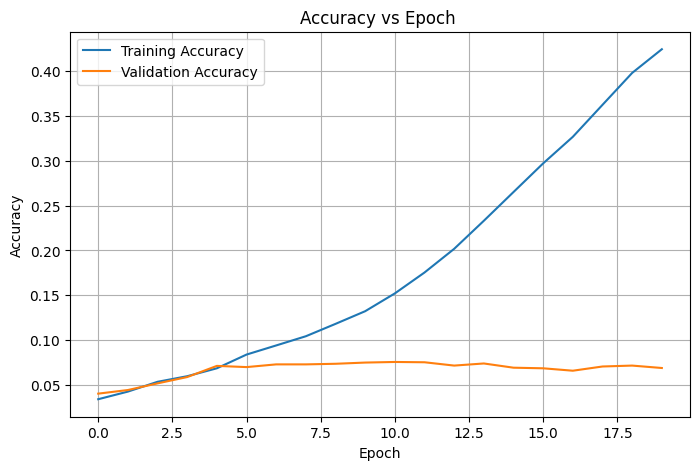

In [17]:
import matplotlib.pyplot as plt

# ---- Accuracy vs Epoch ----
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title(f"Accuracy vs Epoch ")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(f"accuracy_vs_epoch", dpi=150, bbox_inches="tight")
plt.show()


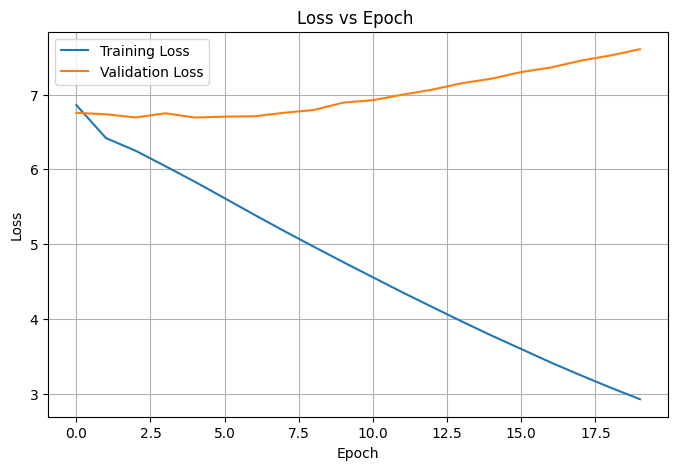

In [18]:
# ---- Loss vs Epoch ----
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title(f"Loss vs Epoch ")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig(f"loss_vs_epoch", dpi=150, bbox_inches="tight")
plt.show()


## PART D: DEEP LEARNING EXPERIMENT MANAGEMENT

In [19]:
def generate_text(seed_text, next_words=30, model=model, max_seq_len=max_seq_len, temperature=1.0):
    """Generate `next_words` additional words after `seed_text` using the trained model."""
    result = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len - 1, padding="pre")

        preds = model.predict(token_list, verbose=0)[0]

        # temperature-scaled sampling for more varied / less repetitive output
        preds = np.log(np.clip(preds, 1e-8, 1.0)) / temperature
        exp_preds = np.exp(preds)
        preds = exp_preds / np.sum(exp_preds)
        predicted_id = np.random.choice(len(preds), p=preds)

        output_word = tokenizer.index_word.get(predicted_id, "")
        if output_word == "":
            break
        result += " " + output_word
    return result


In [20]:
# ---- D.1 - D.3: Provide multiple seed inputs and generate text samples ----
seed_sentences = [
    "to be or not to",
    "the king said unto",
    "love is a",
    "what is thy name",
]

generated_samples = {}
for seed in seed_sentences:
    generated_samples[seed] = generate_text(seed, next_words=25, temperature=0.8)

for seed, generated in generated_samples.items():
    print(f"Seed: {seed!r}")
    print(f"Generated: {generated}")
    print("-" * 80)


Seed: 'to be or not to'
Generated: to be or not to scorn him mouths unbruised be so you looked napes wrench burning become't had late you bedfellow fully transport his tears that craves him first senator
--------------------------------------------------------------------------------
Seed: 'the king said unto'
Generated: the king said unto the field they abhor caught we o' the fliers and the volume him clip you pleased here nourish'd an fellows granted garners clouds foot liking
--------------------------------------------------------------------------------
Seed: 'love is a'
Generated: love is a letter when i may go thither what he lack devise with rushes march ye title day's work earn deeds faced chief it's roman now nor
--------------------------------------------------------------------------------
Seed: 'what is thy name'
Generated: what is thy name to yours your wars of your loves to tire ill blast restrain dined injurious suffer't foremost wagging ransoming mock pleasure bosom's

In [21]:
import pickle

model.save(f"rnn_shakespeare_model.keras")

with open(f"tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
